In [19]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Folder to save the charts
os.makedirs("charts", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [20]:


df = pd.read_csv(r"C:\MyFolder\train.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Convert columns to appropriate data types
df["Order Date"] = pd.to_datetime(
    df["Order Date"].astype(str),
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"].astype(str),
    errors="coerce"
)

df["Sales"] = pd.to_numeric(
    df["Sales"],
    errors="coerce"
)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Remove rows missing essential visualization fields
df = df.dropna(subset=["Order Date", "Sales", "Category"])

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (3959, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,2017-08-11,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,2017-08-11,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,2017-12-06,NaT,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,2016-11-10,NaT,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,2016-11-10,NaT,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


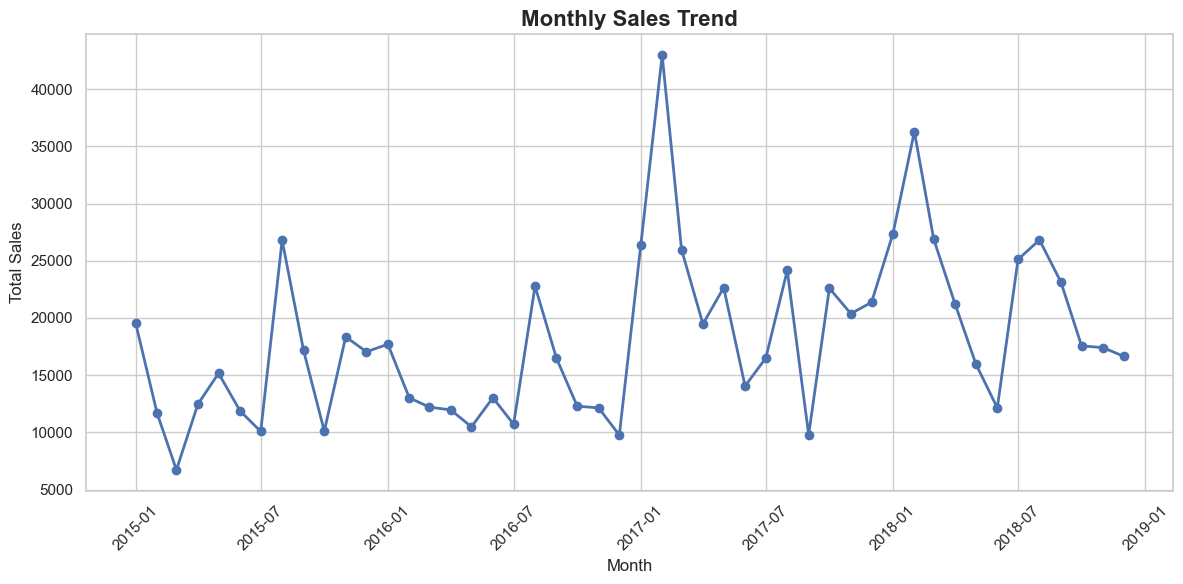

In [30]:
#Monthly sales trend 
#

monthly_sales = (
    df.set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
)

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend", fontsize=16, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\01_monthly_sales_trend.png", dpi=150)
plt.show()

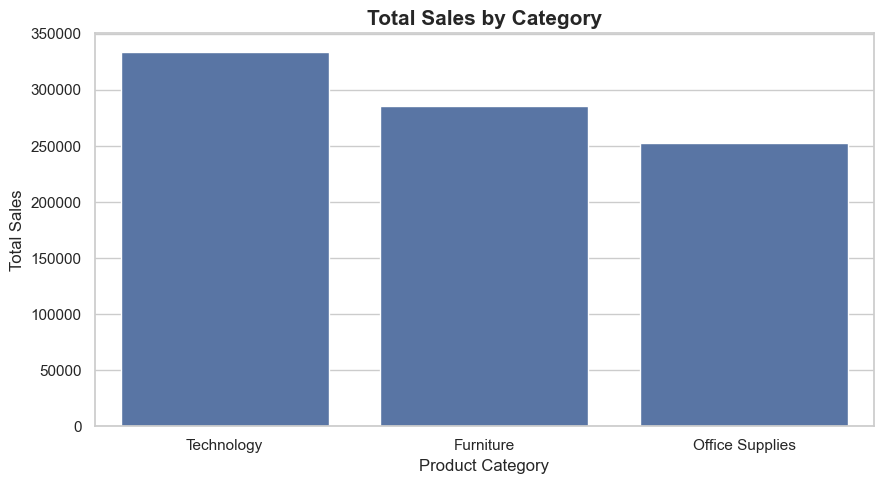

,Category,Total Sales
0,Technology,333844.0900
1,Furniture,285562.8726
2,Office Supplies,252956.1610


In [31]:
#Sales by product category
#How do sales change over time?

category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=category_sales.index, y=category_sales.values)

plt.title("Total Sales by Category", fontsize=15, fontweight="bold")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\02_sales_by_category.png", dpi=150)
plt.show()

display(category_sales.reset_index(name="Total Sales"))

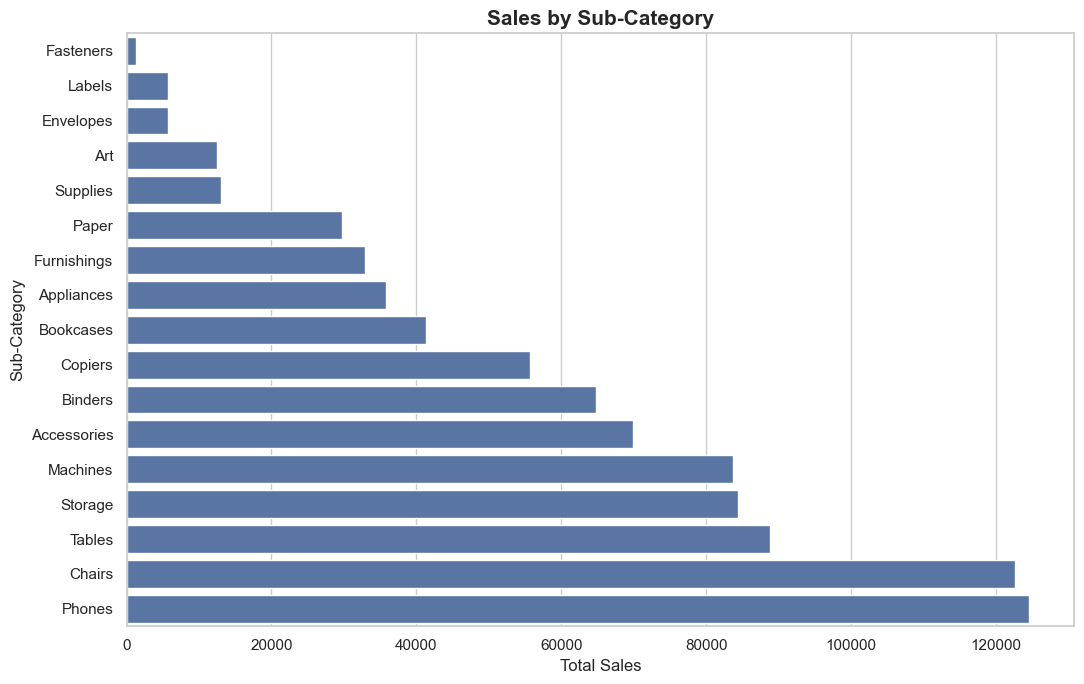

In [32]:
#Chart 3: Sales by sub-category
#Which product sub-categories perform best?

subcategory_sales = (
    df.groupby("Sub-Category")["Sales"]
      .sum()
      .sort_values(ascending=True)
)

plt.figure(figsize=(11, 7))
sns.barplot(
    x=subcategory_sales.values,
    y=subcategory_sales.index
)

plt.title("Sales by Sub-Category", fontsize=15, fontweight="bold")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\03_sales_by_subcategory.png", dpi=150)
plt.show()

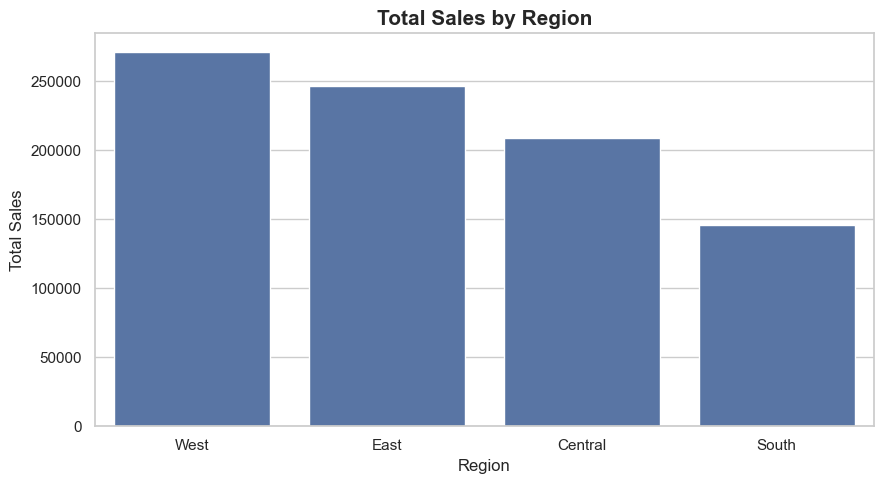

,Region,Total Sales
0,West,271156.6335
1,East,246227.6310
2,Central,208805.0696
3,South,146173.7895


In [33]:
#Chart 4: Sales by region
#Which region contributes the most sales?

region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=region_sales.index, y=region_sales.values)

plt.title("Total Sales by Region", fontsize=15, fontweight="bold")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\04_sales_by_region.png", dpi=150)
plt.show()

display(region_sales.reset_index(name="Total Sales"))

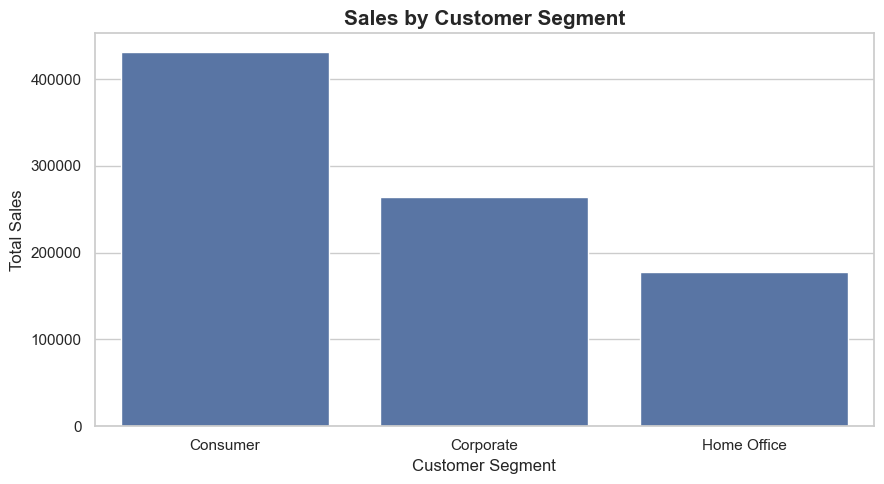

In [36]:
#Chart 5: Sales by customer segment
#Which customer segment contributes the most sales?

segment_sales = (
    df.groupby("Segment")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=segment_sales.index, y=segment_sales.values)

plt.title("Sales by Customer Segment", fontsize=15, fontweight="bold")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\05_sales_by_segment.png", dpi=150)
plt.show()

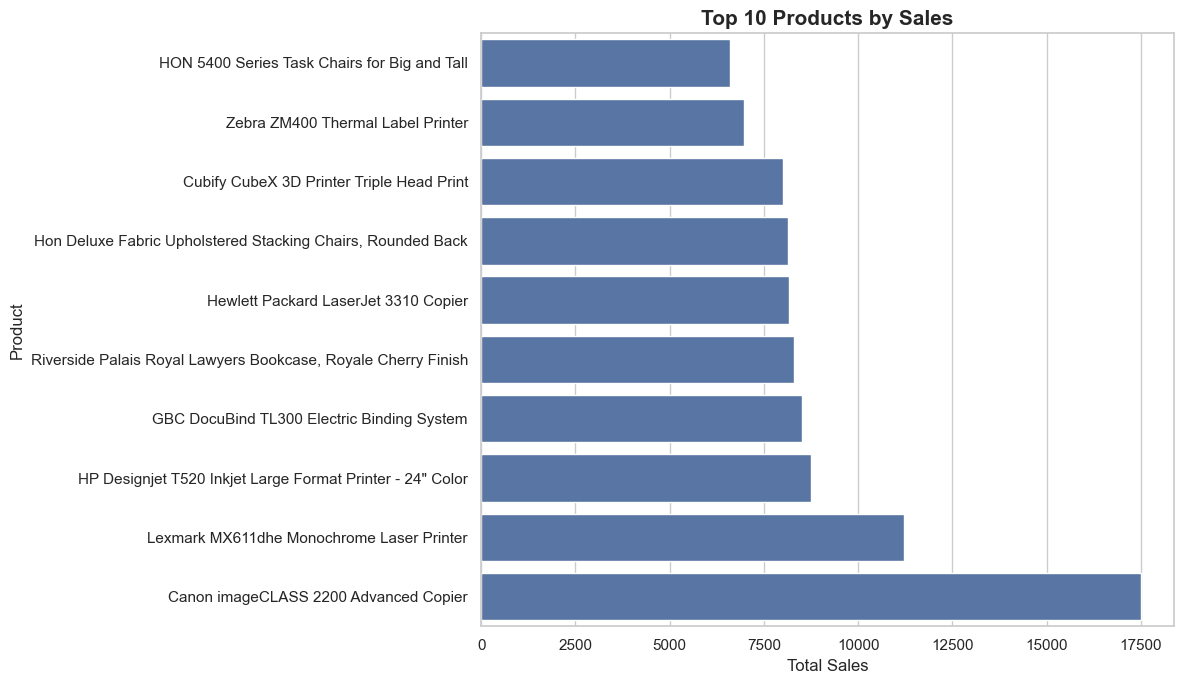

In [35]:
#Chart 6: Top 10 products by sales
#Which products generate the highest sales?

top_products = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .nlargest(10)
      .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_products.values, y=top_products.index)

plt.title("Top 10 Products by Sales", fontsize=15, fontweight="bold")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\06_top_10_products.png", dpi=150)
plt.show()

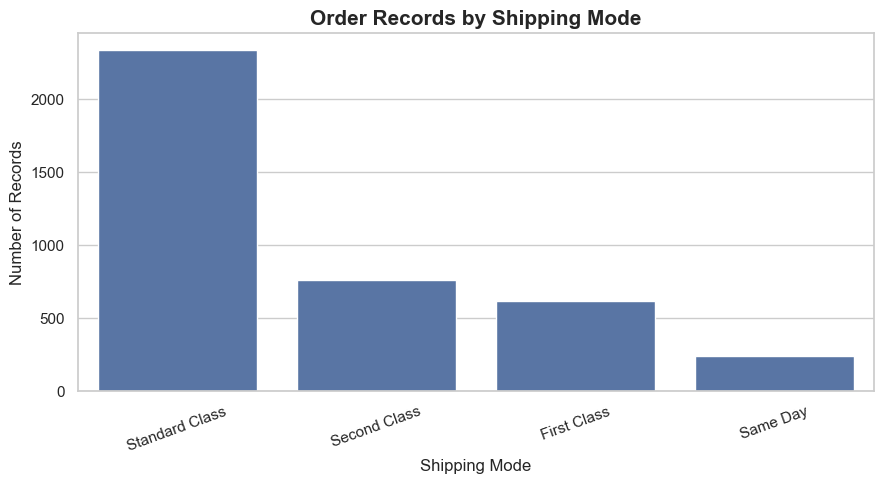

In [37]:
#Chart 7: Orders by shipping mode
#Which shipping mode is used most frequently?

shipping_counts = df["Ship Mode"].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=shipping_counts.index,
    y=shipping_counts.values
)

plt.title("Order Records by Shipping Mode", fontsize=15, fontweight="bold")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\07_shipping_mode.png", dpi=150)
plt.show()

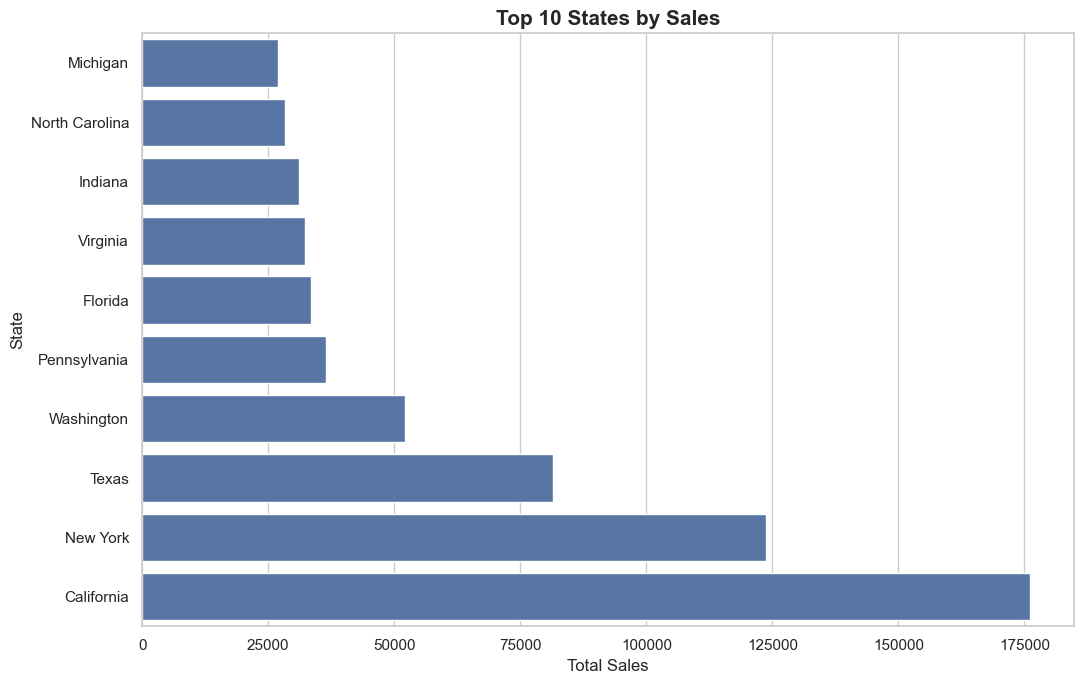

In [38]:
#Top 10 states by sales
#Which states generate the highest sales?

state_sales = (
    df.groupby("State")["Sales"]
      .sum()
      .nlargest(10)
      .sort_values(ascending=True)
)

plt.figure(figsize=(11, 7))
sns.barplot(x=state_sales.values, y=state_sales.index)

plt.title("Top 10 States by Sales", fontsize=15, fontweight="bold")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()

plt.savefig(r"C:\MyFolder\charts\08_top_10_states.png", dpi=150)
plt.show()

In [29]:
print("=" * 50)
print("SUPERSTORE SALES — KEY FINDINGS")
print("=" * 50)

print(f"\nTotal Sales: {df['Sales'].sum():,.2f}")
print(f"Total Records: {len(df):,}")
print(f"Unique Orders: {df['Order ID'].nunique():,}")

print("\n1. Highest-Selling Category:")
print(category_sales.idxmax(),
      f"({category_sales.max():,.2f})")

print("\n2. Highest-Selling Region:")
print(region_sales.idxmax(),
      f"({region_sales.max():,.2f})")

print("\n3. Highest-Selling Customer Segment:")
print(segment_sales.idxmax(),
      f"({segment_sales.max():,.2f})")

print("\n4. Top-Selling Product:")
print(top_products.idxmax(),
      f"({top_products.max():,.2f})")

print("\n5. State with Highest Sales:")
print(state_sales.idxmax(),
      f"({state_sales.max():,.2f})")

print("\n6. Most Common Shipping Mode:")
print(shipping_counts.idxmax(),
      f"({shipping_counts.max():,} records)")

SUPERSTORE SALES — KEY FINDINGS

Total Sales: 872,363.12
Total Records: 3,959
Unique Orders: 1,975

1. Highest-Selling Category:
Technology (333,844.09)

2. Highest-Selling Region:
West (271,156.63)

3. Highest-Selling Customer Segment:
Consumer (431,199.99)

4. Top-Selling Product:
Canon imageCLASS 2200 Advanced Copier (17,499.95)

5. State with Highest Sales:
California (176,044.35)

6. Most Common Shipping Mode:
Standard Class (2,334 records)
